# AI Model Experiment & Evaluation
**Sentiment Analysis Ulasan Pelanggan — Model Klasik (Scikit-learn) vs LLM API (Gemini)**

Penulis: Abi Komara · AI Engineering Bootcamp

Notebook ini dikembangkan dari *starter notebook*. Struktur section 1–8 dipertahankan; beberapa cell tambahan
(pengecekan kualitas data, uji generalisasi, stress test, analisis error) ditambahkan di dalam section yang relevan.

| Komponen | Pilihan |
|---|---|
| Dataset | `data/customer_reviews_sentiment.csv` (200 ulasan, label `positif`/`negatif`) |
| Pendekatan 1 | TF-IDF (unigram + bigram) + Logistic Regression |
| Pendekatan 2 | Gemini API `gemini-3.5-flash-lite`, zero-shot + output terbatas (enum) |
| Evaluasi | Accuracy, Precision, Recall, F1 (macro & per kelas), Confusion Matrix |

## 1. Problem Statement

**Objective.** Tim produk e-commerce ingin fitur otomatis yang mengklasifikasikan sentimen setiap ulasan pelanggan
di halaman produk. Sebelum memilih pendekatan untuk produksi, kita membandingkan dua kandidat secara adil
(test set yang sama) dan menyusun rekomendasi berbasis data.

**Target / label.** Variabel `sentiment` — klasifikasi **biner**:
- `positif` → pelanggan puas (kualitas baik, sesuai deskripsi, pengiriman/pelayanan cepat).
- `negatif` → pelanggan kecewa/mengeluh (rusak/cacat, tidak sesuai, lambat, pelayanan buruk).

Input model hanya `review_text`. Kolom `review_id` dan `product_name` tidak dipakai sebagai fitur (sentimen harus
ditentukan dari isi ulasan, bukan dari nama produk).

**Batasan & asumsi.**
1. Label pada dataset dianggap *ground truth* yang benar.
2. Hanya dua kelas; ulasan netral/campuran dipaksa masuk ke sentimen yang dominan.
3. Dataset kecil (200 baris) dan — seperti terlihat di Section 2 — banyak teks berulang, sehingga hasil
   evaluasi harus dibaca dengan hati-hati.
4. LLM dipakai *as-is* lewat API (tanpa fine-tuning); model klasik dilatih dari nol di dataset ini.
5. Kedua pendekatan dievaluasi pada **test set yang identik** (split 80/20, stratified, `random_state=42`).
6. Dataset asli di `data/` tidak diubah; semua transformasi dilakukan di memori.

## 2. Import Library & Load Dataset

In [1]:
import os
import time
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv, find_dotenv

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)

from google import genai
from google.genai import types

# --- Konstanta eksperimen (satu tempat, mudah diubah & direproduksi) ---
RANDOM_STATE = 42
LABELS = ['negatif', 'positif']

# Path relatif terhadap root project, aman dijalankan dari folder notebook/ maupun root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'customer_reviews_sentiment.csv'
DOC_DIR = PROJECT_ROOT / 'documentation'
DOC_DIR.mkdir(exist_ok=True)

pd.set_option('display.max_colwidth', 90)
sns.set_theme(style='whitegrid')

df = pd.read_csv(DATA_PATH)
df.head()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat dikomplain.,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan barang aman.",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai deskripsi.",positif


### 2.1 Pengecekan Kualitas Data

In [2]:
print('Shape            :', df.shape)
print('Missing values   :', df.isna().sum().to_dict())
print('Distribusi label :', df['sentiment'].value_counts().to_dict())
print(f"Proporsi label   : {df['sentiment'].value_counts(normalize=True).round(3).to_dict()}")

n_unique = df['review_text'].nunique()
print(f"\nTeks ulasan unik : {n_unique} dari {len(df)} baris ({n_unique / len(df):.0%})")
conflict = (df.groupby('review_text')['sentiment'].nunique() > 1).sum()
print('Teks sama tapi label berbeda:', conflict)

print('\n5 teks yang paling sering berulang:')
df['review_text'].value_counts().head()

Shape            : (200, 4)
Missing values   : {'review_id': 0, 'product_name': 0, 'review_text': 0, 'sentiment': 0}
Distribusi label : {'positif': 110, 'negatif': 90}
Proporsi label   : {'positif': 0.55, 'negatif': 0.45}

Teks ulasan unik : 40 dari 200 baris (20%)
Teks sama tapi label berbeda: 0

5 teks yang paling sering berulang:


review_text
Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.                      12
Produknya rapi dan bersih, tidak ada cacat sama sekali.                     9
Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.     8
Kualitas produk jelek, baru dipakai sekali sudah rusak.                     8
Pengiriman lambat sekali, sudah dua minggu belum sampai.                    8
Name: count, dtype: int64

> **Interpretasi.** Tidak ada *missing value* dan label cukup seimbang (55% positif : 45% negatif), jadi accuracy
> masih layak dipakai — tetap didampingi macro-F1 agar kedua kelas dinilai setara.
>
> **Temuan terpenting: hanya 40 dari 200 ulasan yang unik (20%).** Rata-rata tiap kalimat muncul 5×, bahkan ada
> yang muncul 12×. Dataset ini kemungkinan besar disintesis dari ±40 template kalimat. Tidak ada teks yang sama
> dengan label berbeda, jadi labelnya konsisten. Konsekuensinya: split acak hampir pasti menaruh kalimat yang sama
> di train **dan** test.

## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.
`stratify=y` menjaga proporsi positif/negatif sama di train dan test.

In [3]:
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train size:', len(X_train), '| label:', y_train.value_counts().to_dict())
print('Test size :', len(X_test), '| label:', y_test.value_counts().to_dict())

Train size: 160 | label: {'positif': 88, 'negatif': 72}
Test size : 40 | label: {'positif': 22, 'negatif': 18}


In [4]:
# Cek kebocoran (leakage): berapa banyak teks di test set yang PERSIS sama dengan teks di train set?
overlap = X_test.isin(set(X_train))
print(f'{overlap.sum()}/{len(X_test)} ulasan test ({overlap.mean():.0%}) punya teks identik di train set')
print(f'Teks unik di test set: {X_test.nunique()} | yang benar-benar baru (tidak ada di train): {X_test[~overlap].nunique()}')

39/40 ulasan test (98%) punya teks identik di train set
Teks unik di test set: 26 | yang benar-benar baru (tidak ada di train): 1


> **Interpretasi.** 39 dari 40 baris test (98%) teksnya identik dengan data train; dari 26 teks unik di test set,
> hanya 1 yang benar-benar baru. Ini adalah **data leakage**: model yang dilatih bisa "lulus ujian" hanya dengan
> menghafal kalimat. Sesuai brief, split ini tetap dipakai sebagai **evaluasi utama** (identik untuk kedua
> pendekatan), tetapi di **Section 6.5** ditambahkan evaluasi pada teks yang tidak pernah dilihat saat training
> untuk mengukur kemampuan generalisasi yang sebenarnya.

## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

TF-IDF mengubah teks menjadi vektor angka: kata yang sering muncul di satu ulasan tapi jarang di ulasan lain
diberi bobot tinggi. Pilihan parameter:
- `lowercase=True` — "Puas" dan "puas" dianggap sama.
- `ngram_range=(1, 2)` — selain kata tunggal, ambil juga pasangan kata (bigram) agar frasa negasi seperti
  "tidak sesuai" atau "tidak mengecewakan" tertangkap sebagai satu fitur, bukan hanya "tidak" + "sesuai".
- `sublinear_tf=True` — meredam efek kata yang diulang-ulang dalam satu ulasan.

Vectorizer hanya di-`fit` pada **train set**, lalu test set cukup di-`transform` (mencegah kebocoran informasi
dari test set ke model).

In [5]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print('Ukuran vocabulary (fitur):', len(vectorizer.vocabulary_))
print('Shape X_train_vec:', X_train_vec.shape, '| X_test_vec:', X_test_vec.shape)

Ukuran vocabulary (fitur): 384
Shape X_train_vec: (160, 384) | X_test_vec: (40, 384)


### 4.2 Training Model

Logistic Regression dipilih sebagai baseline karena cepat, stabil untuk data kecil berdimensi tinggi (TF-IDF),
dan bisa diinterpretasi (bobot tiap kata terlihat). `max_iter=1000` memastikan solver konvergen.

In [6]:
t0 = time.perf_counter()
clf = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
clf.fit(X_train_vec, y_train)
classic_train_time = time.perf_counter() - t0
print(f'Waktu training: {classic_train_time * 1000:.1f} ms')

Waktu training: 2.4 ms


In [7]:
# Interpretabilitas: kata/frasa dengan bobot paling kuat untuk tiap kelas
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = clf.coef_[0]  # bobot positif -> condong ke kelas clf.classes_[1]
print('classes_:', clf.classes_)
top_n = 10
top_feat = pd.DataFrame({
    f'paling {clf.classes_[0]}': feature_names[np.argsort(coefs)[:top_n]],
    f'paling {clf.classes_[1]}': feature_names[np.argsort(coefs)[::-1][:top_n]],
})
top_feat

classes_: ['negatif' 'positif']


,paling negatif,paling positif
0,lambat,cepat
1,jauh,rapi
2,jauh dari,ada
3,sekali sudah,puas
4,sudah,recommended
5,lambat dan,lebih
6,tidak,cepat dari
7,sekali,lebih cepat
8,rusak,tidak mengecewakan
9,tidak sesuai,dipakai ukuran


### 4.3 Prediksi pada Test Set

In [8]:
t0 = time.perf_counter()
y_pred_classic = clf.predict(vectorizer.transform(X_test))   # transform + predict = biaya inferensi nyata
classic_infer_time = time.perf_counter() - t0
y_pred_classic = pd.Series(y_pred_classic, index=X_test.index, name='pred_classic')

print(f'Inferensi {len(X_test)} ulasan: {classic_infer_time * 1000:.2f} ms '
      f'(~{classic_infer_time / len(X_test) * 1000:.3f} ms per ulasan)')
y_pred_classic.value_counts()

Inferensi 40 ulasan: 0.55 ms (~0.014 ms per ulasan)


pred_classic
positif    22
negatif    18
Name: count, dtype: int64

## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

API key dibaca dari file `.env` (lihat `.env.example`) — **tidak** di-hardcode di notebook dan `.env` sudah
masuk `.gitignore` sehingga tidak ikut ter-push ke GitHub.

In [9]:
load_dotenv(find_dotenv(usecwd=True))   # cari .env dari folder kerja ke atas
api_key = os.getenv('GEMINI_API_KEY')

# Cache hasil LLM di disk: re-run notebook tidak memanggil API lagi (hemat kuota, hasil konsisten,
# dan mentor tetap bisa menjalankan notebook tanpa API key selama cache lengkap).
CACHE_PATH = DOC_DIR / 'llm_predictions_cache.json'

if api_key:
    client = genai.Client(api_key=api_key)
else:
    client = None
    print('WARNING: GEMINI_API_KEY not found -> only cached LLM predictions can be used. '
          'Copy .env.example to .env and fill in your API key to call the API.')

# --- Parameter LLM ---
LLM_MODEL = 'gemini-3.5-flash-lite'  # versi dipin eksplisit (bukan alias "latest") agar hasil reproducible
TEMPERATURE = 0.0                    # klasifikasi butuh jawaban deterministik, bukan kreativitas
MIN_INTERVAL_SEC = 4.0               # jeda antar request agar aman dari rate limit free tier

# Harga paid tier (Standard) Gemini 3.5 Flash-Lite per 1 juta token, USD — cek ai.google.dev/gemini-api/docs/pricing
PRICE_INPUT_PER_1M = 0.30
PRICE_OUTPUT_PER_1M = 2.50
print('Client siap. Model:', LLM_MODEL)

Client siap. Model: gemini-3.5-flash-lite


### 5.2 Merancang Prompt

**Teknik: zero-shot dengan definisi label yang eksplisit + output terbatas (constrained output).**

Struktur prompt:
1. **System instruction** — peran, definisi tiap label, dan aturan untuk kasus sulit (negasi, sarkasme,
   ulasan campuran). Dipisah dari data agar instruksi tidak tercampur dengan isi ulasan.
2. **User content** — hanya ulasan yang akan diklasifikasi.
3. **Constrained output** — `response_mime_type="text/x.enum"` + `response_schema` berisi
   `["negatif", "positif"]`, sehingga model *secara teknis* hanya bisa menjawab salah satu label.
   Ini mencegah jawaban seperti "Sentimen: Positif." yang harus di-parse manual.

**Kenapa zero-shot, bukan few-shot?**
- Sentimen biner adalah tugas yang sudah sangat dikuasai LLM; definisi label yang jelas biasanya cukup.
- Few-shot menambah token input di *setiap* panggilan → biaya & latency naik.
- Dataset ini sangat repetitif; contoh few-shot yang diambil dari train set berisiko hampir identik dengan
  teks di test set, sehingga hasil LLM ikut "bocor" dan perbandingan jadi tidak adil.
- Contoh di aturan negasi/sarkasme sengaja memakai kalimat yang **tidak** ada di dataset.

**Parameter:** `temperature=0.0` → output paling deterministik (klasifikasi butuh konsistensi: ulasan yang sama
harus selalu mendapat label yang sama). Starter memakai 0.2; untuk task klasifikasi tidak ada manfaat variasi,
jadi diturunkan ke 0.

In [10]:
SYSTEM_INSTRUCTION = """Kamu adalah sistem klasifikasi sentimen untuk ulasan produk e-commerce berbahasa Indonesia.

Tugas: tentukan sentimen KESELURUHAN dari ulasan pelanggan.

Label:
- "positif": pelanggan puas atau merekomendasikan (kualitas baik, sesuai deskripsi, pengiriman/pelayanan cepat, harga sepadan).
- "negatif": pelanggan kecewa atau mengeluh (barang rusak/cacat/palsu, tidak sesuai, pengiriman lambat, pelayanan buruk).

Aturan:
1. Perhatikan negasi. Contoh: "tidak buruk" -> positif, "tidak bisa menyala" -> negatif.
2. Perhatikan sarkasme. Pujian yang disertai keluhan nyata dihitung negatif.
3. Jika ulasan campuran, pilih sentimen yang paling dominan atau kesimpulan akhir pelanggan.
4. Jawab hanya dengan satu label: positif atau negatif."""

def build_user_prompt(review_text: str) -> str:
    return f'Ulasan: "{review_text}"'

GEN_CONFIG = types.GenerateContentConfig(
    system_instruction=SYSTEM_INSTRUCTION,
    temperature=TEMPERATURE,
    response_mime_type='text/x.enum',
    response_schema={'type': 'STRING', 'enum': LABELS},
    automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True),
)

print(SYSTEM_INSTRUCTION)
print('\nContoh user prompt ->', build_user_prompt(X_test.iloc[0]))

Kamu adalah sistem klasifikasi sentimen untuk ulasan produk e-commerce berbahasa Indonesia.

Tugas: tentukan sentimen KESELURUHAN dari ulasan pelanggan.

Label:
- "positif": pelanggan puas atau merekomendasikan (kualitas baik, sesuai deskripsi, pengiriman/pelayanan cepat, harga sepadan).
- "negatif": pelanggan kecewa atau mengeluh (barang rusak/cacat/palsu, tidak sesuai, pengiriman lambat, pelayanan buruk).

Aturan:
1. Perhatikan negasi. Contoh: "tidak buruk" -> positif, "tidak bisa menyala" -> negatif.
2. Perhatikan sarkasme. Pujian yang disertai keluhan nyata dihitung negatif.
3. Jika ulasan campuran, pilih sentimen yang paling dominan atau kesimpulan akhir pelanggan.
4. Jawab hanya dengan satu label: positif atau negatif.

Contoh user prompt -> Ulasan: "Barang tidak berfungsi sama sekali begitu diterima."


In [11]:
def normalize_label(raw):
    """Normalisasi output LLM -> 'positif' / 'negatif' / 'unknown' (lapisan pengaman kedua setelah enum)."""
    if raw is None:
        return 'unknown'
    text = raw.strip().lower().strip('."\' \n')
    if text in LABELS:
        return text
    if 'negatif' in text or 'negative' in text:
        return 'negatif'
    if 'positif' in text or 'positive' in text:
        return 'positif'
    return 'unknown'

import json
import hashlib

# Cache key = model + temperature + hash prompt + teks -> cache otomatis diabaikan bila prompt/model diubah
hash_prompt = hashlib.md5(SYSTEM_INSTRUCTION.encode()).hexdigest()[:8]
def _cache_key(review_text):
    return f'{LLM_MODEL}|T={TEMPERATURE}|{hash_prompt}|{review_text}'

_disk_cache = json.loads(CACHE_PATH.read_text()) if CACHE_PATH.exists() else {}
_llm_cache = {}     # cache sesi ini: teks sama tidak dipanggil ulang
llm_call_log = []   # catatan tiap teks unik: raw output, latency (saat panggilan asli), token, sumber
_last_call = [0.0]
print(f'Cache di disk: {len(_disk_cache)} entri')

def classify_sentiment_llm(review_text, max_retries=5):
    """Klasifikasi satu ulasan via Gemini. Return label ternormalisasi."""
    if review_text in _llm_cache:
        return _llm_cache[review_text]

    key = _cache_key(review_text)
    if key in _disk_cache:                       # sudah pernah dipanggil di run sebelumnya
        rec = {**_disk_cache[key], 'source': 'disk-cache'}
        llm_call_log.append(rec)
        _llm_cache[review_text] = rec['label']
        return rec['label']
    if client is None:
        raise RuntimeError('No API key and no cached prediction for this review. Set GEMINI_API_KEY in .env.')

    raw, latency, usage = None, None, None
    for attempt in range(max_retries):
        wait = MIN_INTERVAL_SEC - (time.time() - _last_call[0])   # throttle sederhana
        if wait > 0:
            time.sleep(wait)
        try:
            t0 = time.perf_counter()
            _last_call[0] = time.time()
            response = client.models.generate_content(
                model=LLM_MODEL, contents=build_user_prompt(review_text), config=GEN_CONFIG
            )
            latency = time.perf_counter() - t0
            raw, usage = response.text, response.usage_metadata
            break
        except Exception as e:   # rate limit / server error -> exponential backoff
            backoff = 5 * 2 ** attempt
            print(f'  [retry {attempt + 1}] {type(e).__name__}: {str(e)[:90]} -> tunggu {backoff}s')
            time.sleep(backoff)

    label = normalize_label(raw)
    rec = {
        'review_text': review_text, 'raw_output': raw, 'label': label,
        'latency_sec': latency,
        'input_tokens': getattr(usage, 'prompt_token_count', None),
        'output_tokens': getattr(usage, 'candidates_token_count', None),
    }
    if raw is not None:                          # hanya simpan panggilan yang sukses
        _disk_cache[key] = rec
        CACHE_PATH.write_text(json.dumps(_disk_cache, ensure_ascii=False, indent=1))
    llm_call_log.append({**rec, 'source': 'api'})
    _llm_cache[review_text] = label
    return label

# Sanity check 1 panggilan
print(classify_sentiment_llm(X_test.iloc[0]), '<- label asli:', y_test.iloc[0])

Cache di disk: 50 entri
negatif <- label asli: negatif


### 5.3 Menjalankan Prediksi pada Test Set

Setiap ulasan di `X_test` (test set yang **sama** dengan model klasik) dikirim ke Gemini. Output langsung
dinormalisasi oleh `normalize_label()` (lowercase, strip whitespace/tanda baca, mapping ke label valid).
Karena ada teks duplikat, hasil di-*cache*: teks yang sama cukup dipanggil sekali. Cache juga disimpan ke
`documentation/llm_predictions_cache.json`, sehingga menjalankan ulang notebook tidak menghabiskan kuota API dan
hasilnya identik (latency yang dilaporkan tetap latency panggilan API aslinya).

In [12]:
t0 = time.perf_counter()
y_pred_llm = []
for i, review in enumerate(X_test, 1):
    y_pred_llm.append(classify_sentiment_llm(review))
    if i % 10 == 0:
        print(f'{i}/{len(X_test)} selesai')
llm_wall_time = time.perf_counter() - t0

y_pred_llm = pd.Series(y_pred_llm, index=X_test.index, name='pred_llm')
src = pd.Series([r['source'] for r in llm_call_log]).value_counts().to_dict()
print(f'\nTeks unik yang diklasifikasi: {len(llm_call_log)} (dari {len(X_test)} baris test) | sumber: {src} | '
      f'output tidak valid (unknown): {(y_pred_llm == "unknown").sum()}')
print(f'Total waktu loop sesi ini: {llm_wall_time:.1f} s (≈0 s bila semua prediksi diambil dari cache)')
y_pred_llm.value_counts()

10/40 selesai
20/40 selesai
30/40 selesai
40/40 selesai

Teks unik yang diklasifikasi: 26 (dari 40 baris test) | sumber: {'disk-cache': 26} | output tidak valid (unknown): 0
Total waktu loop sesi ini: 0.0 s (≈0 s bila semua prediksi diambil dari cache)


pred_llm
positif    22
negatif    18
Name: count, dtype: int64

In [13]:
# Catat hasil prediksi kedua pendekatan untuk keperluan evaluasi & audit
predictions = df.loc[X_test.index, ['review_id', 'product_name', 'review_text', 'sentiment']].copy()
predictions['pred_classic'] = y_pred_classic
predictions['pred_llm'] = y_pred_llm
predictions.to_csv(DOC_DIR / 'test_predictions.csv', index=False)
print('Tersimpan ->', (DOC_DIR / 'test_predictions.csv').relative_to(PROJECT_ROOT))
predictions.head(10)

Tersimpan -> documentation/test_predictions.csv


,review_id,product_name,review_text,sentiment,pred_classic,pred_llm
189,190,Headset Bluetooth,Barang tidak berfungsi sama sekali begitu diterima.,negatif,negatif,negatif
68,69,Charger Cepat,"Sudah langganan di toko ini, kualitas selalu konsisten bagus.",positif,positif,positif
115,116,Headset Bluetooth,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif,positif
69,70,Lampu LED,"Kualitas produk sangat memuaskan, akan order lagi.",positif,positif,positif
173,174,Rice Cooker,"Ukuran tidak sesuai, terlalu kecil dari yang dipesan.",negatif,negatif,negatif
6,7,Powerbank,Sudah bayar mahal tapi kualitas jauh dari ekspektasi.,negatif,negatif,negatif
71,72,Headset Bluetooth,"Suka banget sama warnanya, sesuai ekspektasi.",positif,positif,positif
54,55,Tas Ransel,"Fast respon, pengiriman cepat, barang aman sampai tujuan.",positif,positif,positif
74,75,Jaket Hoodie,"Produk palsu, bukan barang original seperti yang dijanjikan.",negatif,negatif,negatif
114,115,Kemeja Flanel,Komplain tidak ditanggapi sama sekali oleh penjual.,negatif,negatif,negatif


## 6. Evaluasi dan Perbandingan

Arti metrik (kelas `negatif` penting secara bisnis karena ulasan negatif perlu ditindaklanjuti):
- **Accuracy** — proporsi prediksi yang benar dari seluruh test set.
- **Precision** — dari semua yang diprediksi kelas X, berapa persen yang benar-benar X (*seberapa bisa dipercaya*).
- **Recall** — dari semua yang sebenarnya kelas X, berapa persen yang berhasil ditemukan (*seberapa lengkap*).
- **F1-Score** — rata-rata harmonik precision & recall; seimbang bila salah satu rendah.
- **Macro average** — rata-rata antar kelas tanpa bobot, adil walau jumlah kelas sedikit tidak seimbang (110 vs 90).
- **Confusion matrix** — baris = label aktual, kolom = prediksi; diagonal = benar, di luar diagonal = salah.

In [14]:
def evaluate(name, y_true, y_pred):
    """Cetak metrik lengkap + kembalikan ringkasan dict."""
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    p_c, r_c, f1_c, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    print(f'=== {name} ===')
    print(f'Accuracy: {acc:.4f}\n')
    print(classification_report(y_true, y_pred, labels=LABELS, digits=4, zero_division=0))
    print('Confusion Matrix (baris = aktual, kolom = prediksi):')
    print(pd.DataFrame(cm, index=[f'aktual_{l}' for l in LABELS], columns=[f'pred_{l}' for l in LABELS]))
    return {'Pendekatan': name, 'Accuracy': acc,
            'Precision (macro)': p, 'Recall (macro)': r, 'F1 (macro)': f1,
            'Recall negatif': r_c[0], 'F1 negatif': f1_c[0], 'cm': cm}

### 6.1 Evaluasi Model Klasik

In [15]:
res_classic = evaluate('Model Klasik (TF-IDF + LogReg)', y_test, y_pred_classic)

=== Model Klasik (TF-IDF + LogReg) ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            18             0
aktual_positif             0            22


> **Interpretasi.** Model klasik memprediksi seluruh 40 ulasan dengan benar: accuracy, precision, recall, dan F1
> bernilai 1.00 untuk kedua kelas. Confusion matrix tidak berisi *false positive* maupun *false negative* —
> tidak ada ulasan negatif yang terlewat (recall negatif 1.00) dan tidak ada ulasan positif yang salah dicap
> negatif (precision negatif 1.00).
>
> **Namun angka ini harus dibaca dengan skeptis.** Karena 98% teks test sudah ada di train set, skor sempurna ini
> lebih mencerminkan hafalan daripada pemahaman. Section 6.5 menguji hal ini secara langsung.

### 6.2 Evaluasi LLM API

In [16]:
res_llm = evaluate(f'LLM API ({LLM_MODEL})', y_test, y_pred_llm)

=== LLM API (gemini-3.5-flash-lite) ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        18
     positif     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            18             0
aktual_positif             0            22


> **Interpretasi.** Gemini juga benar untuk seluruh 40 ulasan (precision/recall/F1 = 1.00 di kedua kelas) dan tidak
> ada satu pun output di luar label (`unknown` = 0) berkat *constrained output*. Bedanya, LLM **tidak pernah melihat
> data train**, sehingga skor ini tidak dipengaruhi leakage — ini murni kemampuan zero-shot.
>
> Catatan: kalimat di dataset ini jelas dan eksplisit (tanpa sarkasme atau ambiguitas), jadi bagi LLM ini termasuk
> soal mudah. Skor 1.00 di sini belum menjamin performa yang sama pada ulasan nyata.

### 6.3 Tabel Perbandingan Ringkasan

In [17]:
# --- Metrik performa ---
metric_cols = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)', 'Recall negatif', 'F1 negatif']
comparison = pd.DataFrame([res_classic, res_llm]).set_index('Pendekatan')[metric_cols].round(4)

# --- Metrik operasional ---
log_df = pd.DataFrame(llm_call_log)
avg_latency = log_df['latency_sec'].mean()
avg_in, avg_out = log_df['input_tokens'].mean(), log_df['output_tokens'].mean()
cost_per_review = (avg_in * PRICE_INPUT_PER_1M + avg_out * PRICE_OUTPUT_PER_1M) / 1e6

operational = pd.DataFrame({
    'Butuh data berlabel & training': ['Ya', 'Tidak'],
    'Waktu training': [f'{classic_train_time * 1000:.0f} ms', '-'],
    'Latency per ulasan': [f'{classic_infer_time / len(X_test) * 1000:.3f} ms', f'{avg_latency * 1000:.0f} ms'],
    'Biaya per 1.000 ulasan (USD)': ['~0 (CPU lokal)', f'{cost_per_review * 1000:.4f}'],
    'Biaya per 1 juta ulasan (USD)': ['~0 (CPU lokal)', f'{cost_per_review * 1e6:.2f}'],
}, index=comparison.index)

print(f'Rata-rata token per panggilan LLM: input {avg_in:.0f}, output {avg_out:.0f}')
comparison.to_csv(DOC_DIR / 'model_comparison.csv')
operational.to_csv(DOC_DIR / 'operational_comparison.csv')
display(comparison)
display(operational)

Rata-rata token per panggilan LLM: input 212, output 2


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall negatif,F1 negatif
Pendekatan,,,,,,
Model Klasik (TF-IDF + LogReg),1.0,1.0,1.0,1.0,1.0,1.0
LLM API (gemini-3.5-flash-lite),1.0,1.0,1.0,1.0,1.0,1.0


,Butuh data berlabel & training,Waktu training,Latency per ulasan,Biaya per 1.000 ulasan (USD),Biaya per 1 juta ulasan (USD)
Pendekatan,,,,,
Model Klasik (TF-IDF + LogReg),Ya,2 ms,0.014 ms,~0 (CPU lokal),~0 (CPU lokal)
LLM API (gemini-3.5-flash-lite),Tidak,-,1003 ms,0.0685,68.47


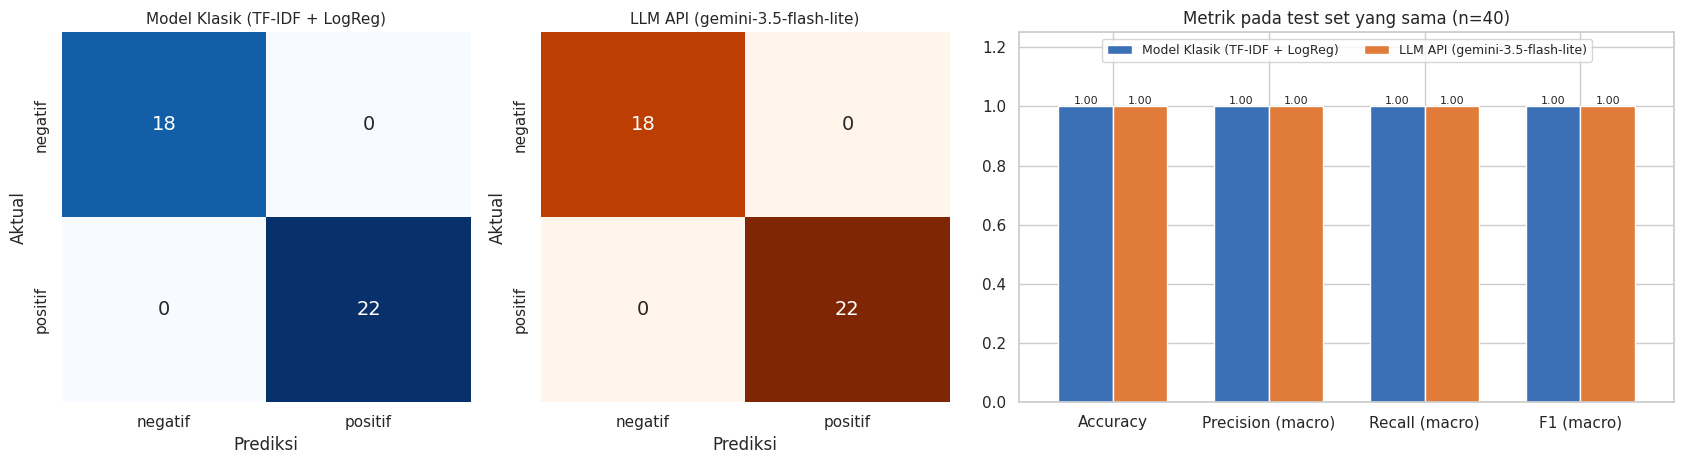

In [18]:
# Visual ringkasan -> documentation/model_comparison_summary.png
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1, 1, 1.6]})
for ax, res, cmap in zip(axes[:2], [res_classic, res_llm], ['Blues', 'Oranges']):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS, annot_kws={'size': 14})
    ax.set_title(res['Pendekatan'], fontsize=11)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')

plot_df = comparison[['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']].T
plot_df.plot(kind='bar', ax=axes[2], color=['#3B6FB6', '#E07B39'], rot=0, width=0.7)
axes[2].set_ylim(0, 1.25); axes[2].set_title('Metrik pada test set yang sama (n=40)')
axes[2].legend(loc='upper center', ncol=2, fontsize=9)
for c in axes[2].containers:
    axes[2].bar_label(c, fmt='%.2f', fontsize=8)
plt.tight_layout()
fig.savefig(DOC_DIR / 'confusion_matrix_test_set.png', dpi=150, bbox_inches='tight')
plt.show()

> **Interpretasi.** Di test set utama kedua pendekatan **seri sempurna** (semua metrik 1.00), sehingga metrik
> performa pada split ini tidak bisa membedakan keduanya. Perbedaan justru muncul di sisi operasional:
> - **Latency:** model klasik < 0,1 ms per ulasan di CPU lokal; LLM ~1 detik per ulasan (network round-trip) —
>   puluhan ribu kali lebih lambat.
> - **Biaya:** model klasik praktis gratis; LLM ±USD 0,07 per 1.000 ulasan (≈ USD 68 per 1 juta ulasan) dengan
>   ~212 token input dan 2 token output per panggilan, berdasarkan harga paid tier Gemini 3.5 Flash-Lite.
>   Sebagian besar biaya berasal dari system instruction yang dikirim ulang di setiap panggilan.
>
> Karena skornya seri **dan** split ini bocor, keputusan tidak boleh diambil dari tabel ini saja → lanjut ke uji
> generalisasi (6.5) dan stress test (6.6).

### 6.4 Analisis Kesalahan Prediksi

Melihat langsung ulasan yang salah diprediksi lebih informatif daripada angka saja.

In [19]:
errors = predictions[(predictions['pred_classic'] != predictions['sentiment']) |
                     (predictions['pred_llm'] != predictions['sentiment'])]
print(f'Salah oleh model klasik: {(predictions.pred_classic != predictions.sentiment).sum()} | '
      f'salah oleh LLM: {(predictions.pred_llm != predictions.sentiment).sum()}')
errors if len(errors) else print('Tidak ada kesalahan prediksi pada test set ini.')

Salah oleh model klasik: 0 | salah oleh LLM: 0
Tidak ada kesalahan prediksi pada test set ini.


> **Interpretasi.** Tidak ada kesalahan prediksi di test set utama untuk kedua pendekatan. Karena itu analisis
> kesalahan dilakukan pada uji tambahan di bawah (6.5 dan 6.6), di mana perbedaan keduanya baru terlihat.

### 6.5 Uji Tambahan — Generalisasi pada Teks yang Belum Pernah Dilihat

Section 3 menunjukkan sebagian besar teks test set juga ada di train set, sehingga skor model klasik di atas
lebih mengukur **kemampuan menghafal** daripada kemampuan memahami ulasan baru. Di produksi, ulasan baru
hampir selalu berupa kalimat yang belum pernah dilihat.

Untuk mengukurnya, dipakai `StratifiedGroupKFold` (5 fold) dengan `groups=review_text`: semua duplikat dari
satu teks selalu berada di fold yang sama, sehingga **teks di fold uji tidak pernah muncul saat training**.
Evaluasi dilakukan per teks unik (40 teks → masing-masing tepat sekali menjadi data uji). LLM tidak dilatih,
jadi prediksinya cukup diambil (dari cache, atau dipanggil bila belum pernah).

In [20]:
unique_df = df.drop_duplicates('review_text').set_index('review_text')['sentiment']
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows, oof = [], []
for fold, (tr_idx, te_idx) in enumerate(sgkf.split(df['review_text'], df['sentiment'], groups=df['review_text']), 1):
    tr, te = df.iloc[tr_idx], df.iloc[te_idx]
    assert not set(tr['review_text']) & set(te['review_text'])      # benar-benar tidak ada overlap

    vec_g = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
    clf_g = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    clf_g.fit(vec_g.fit_transform(tr['review_text']), tr['sentiment'])

    te_texts = te['review_text'].unique()
    y_true_g = unique_df.loc[te_texts]
    pred_c = clf_g.predict(vec_g.transform(te_texts))
    pred_l = [classify_sentiment_llm(t) for t in te_texts]

    fold_rows.append({'fold': fold, 'n_teks_uji': len(te_texts),
                      'acc_klasik': accuracy_score(y_true_g, pred_c),
                      'acc_llm': accuracy_score(y_true_g, pred_l)})
    oof += [{'review_text': t, 'sentiment': yt, 'pred_classic': pc, 'pred_llm': pl}
            for t, yt, pc, pl in zip(te_texts, y_true_g, pred_c, pred_l)]

fold_df = pd.DataFrame(fold_rows)
oof_df = pd.DataFrame(oof)
print(fold_df.round(3).to_string(index=False))
print(f"\nRata-rata ± std accuracy  | Klasik: {fold_df.acc_klasik.mean():.3f} ± {fold_df.acc_klasik.std():.3f}"
      f"  | LLM: {fold_df.acc_llm.mean():.3f} ± {fold_df.acc_llm.std():.3f}")

 fold  n_teks_uji  acc_klasik  acc_llm
    1           8       0.625      1.0
    2           9       0.444      1.0
    3           7       0.429      1.0
    4           8       0.375      1.0
    5           8       0.625      1.0

Rata-rata ± std accuracy  | Klasik: 0.500 ± 0.117  | LLM: 1.000 ± 0.000


In [21]:
res_classic_g = evaluate('Model Klasik — teks belum pernah dilihat', oof_df['sentiment'], oof_df['pred_classic'])
print()
res_llm_g = evaluate('LLM API — teks belum pernah dilihat', oof_df['sentiment'], oof_df['pred_llm'])

generalization = pd.DataFrame([res_classic_g, res_llm_g]).set_index('Pendekatan')[metric_cols].round(4)
generalization.to_csv(DOC_DIR / 'generalization_comparison.csv')
display(generalization)
print('\nTeks yang salah diprediksi:')
oof_df[(oof_df.pred_classic != oof_df.sentiment) | (oof_df.pred_llm != oof_df.sentiment)]

=== Model Klasik — teks belum pernah dilihat ===
Accuracy: 0.5000

              precision    recall  f1-score   support

     negatif     0.5000    0.5000    0.5000        20
     positif     0.5000    0.5000    0.5000        20

    accuracy                         0.5000        40
   macro avg     0.5000    0.5000    0.5000        40
weighted avg     0.5000    0.5000    0.5000        40

Confusion Matrix (baris = aktual, kolom = prediksi):
                pred_negatif  pred_positif
aktual_negatif            10            10
aktual_positif            10            10

=== LLM API — teks belum pernah dilihat ===
Accuracy: 1.0000

              precision    recall  f1-score   support

     negatif     1.0000    1.0000    1.0000        20
     positif     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40

Confusion Matrix (baris = aktual, 

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall negatif,F1 negatif
Pendekatan,,,,,,
Model Klasik — teks belum pernah dilihat,0.5,0.5,0.5,0.5,0.5,0.5
LLM API — teks belum pernah dilihat,1.0,1.0,1.0,1.0,1.0,1.0



Teks yang salah diprediksi:


,review_text,sentiment,pred_classic,pred_llm
3,"Kualitas produk sangat memuaskan, akan order lagi.",positif,negatif,positif
4,"Pelayanan ramah dan responsif, barang sampai lebih cepat dari estimasi.",positif,negatif,positif
5,"Barang datang lebih cepat dari perkiraan, kualitas top!",positif,negatif,positif
10,"Belanja disini selalu puas, kualitas terjaga.",positif,negatif,positif
11,"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",positif,negatif,positif
12,"Sudah langganan di toko ini, kualitas selalu konsisten bagus.",positif,negatif,positif
14,"Suka banget sama warnanya, sesuai ekspektasi.",positif,negatif,positif
15,"Kualitas premium dengan harga bersahabat, recommended!",positif,negatif,positif
18,"Kualitas produk jelek, baru dipakai sekali sudah rusak.",negatif,positif,negatif
19,"Produknya rapi dan bersih, tidak ada cacat sama sekali.",positif,negatif,positif


> **Interpretasi — temuan kunci eksperimen ini.**
> - Ketika kalimat uji benar-benar baru, accuracy model klasik **turun dari 1.00 menjadi 0.50** (0.50 ± 0.12 antar
>   fold) — setara lempar koin. Confusion matrix 10/10/10/10 menunjukkan model sama sekali tidak bisa membedakan
>   kelas. Recall negatif juga hanya 0.50: separuh keluhan pelanggan akan terlewat.
> - LLM tetap **1.00 di semua fold**, karena kemampuannya tidak bergantung pada kalimat yang pernah dilihat.
>
> **Kenapa model klasik gagal?** (dicek dari kontribusi bobot tiap fitur TF-IDF pada fold terkait)
> - *"Kualitas produk sangat memuaskan, akan order lagi."* → diprediksi **negatif**. Kata "memuaskan" tidak ada di
>   vocabulary training fold itu, sementara frasa "akan order lagi" hanya pernah muncul di ulasan negatif
>   *"...tidak akan order lagi disini."*
> - Kebalikannya, *"Pengalaman belanja terburuk, tidak akan order lagi disini."* → diprediksi **positif**. Kata
>   "terburuk" tidak dikenal, sedangkan "akan order lagi" dipelajari dari ulasan positif.
> - *"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan."* → **negatif**. "nyaman", "pas", dan "mengecewakan"
>   tidak dikenal; yang tersisa hanya "tidak", "ukuran", "dipakai", "bahan" yang di data train muncul di keluhan.
> - *"Barang tidak berfungsi sama sekali begitu diterima."* → **positif**, karena "berfungsi" dipelajari dari
>   ulasan positif *"Produk original dan berfungsi dengan baik"*.
>
> Kesimpulannya, TF-IDF + Logistic Regression belajar **asosiasi kata kunci, bukan makna**. Dengan hanya ±32
> kalimat unik untuk training, vocabulary-nya terlalu sempit: kata baru diabaikan, dan keputusan ditentukan oleh
> sedikit kata yang kebetulan muncul di konteks kelas lain. Masalah utamanya adalah **kurangnya variasi data**,
> bukan algoritmanya — model yang sama bisa jauh lebih baik jika dilatih pada ribuan ulasan nyata yang beragam.

### 6.6 Stress Test — Kalimat Sulit di Luar Dataset

Ulasan nyata jauh lebih beragam dibanding dataset ini (yang kalimatnya rapi dan berulang). Berikut 10 kalimat
buatan sendiri yang sengaja mengandung pola sulit: negasi, sarkasme, ulasan campuran, slang, dan kosakata baru.
Label ditentukan manual oleh penulis (asumsi *ground truth*), jadi ini **uji kualitatif**, bukan metrik utama.

In [22]:
hard_cases = pd.DataFrame([
    ('Barangnya tidak jelek, lumayan banget untuk harga segini.',     'positif', 'negasi'),
    ('Wah hebat, baru sehari dipakai sudah rusak. Mantap sekali.',    'negatif', 'sarkasme'),
    ('Pengiriman agak lama, tapi kualitas barangnya bagus sekali.',   'positif', 'campuran'),
    ('Barangnya sih oke, tapi pelayanan penjualnya bikin kapok.',     'negatif', 'campuran'),
    ('brg ori gan, mantul, pengiriman kilat',                          'positif', 'slang'),
    ('Nyesel beli di sini, mending cari toko lain aja.',              'negatif', 'kosakata baru'),
    ('Worth it parah, anak saya suka banget.',                         'positif', 'slang'),
    ('Tidak sesuai harapan, tidak akan beli lagi.',                    'negatif', 'negasi'),
    ('Awalnya ragu, ternyata produknya bagus dan awet.',               'positif', 'campuran'),
    ('Katanya original, ternyata KW. Zonk.',                           'negatif', 'slang'),
], columns=['review_text', 'label_manual', 'pola'])

hard_cases['pred_classic'] = clf.predict(vectorizer.transform(hard_cases['review_text']))
hard_cases['pred_llm'] = [classify_sentiment_llm(t) for t in hard_cases['review_text']]
hard_cases['klasik_benar'] = hard_cases['pred_classic'] == hard_cases['label_manual']
hard_cases['llm_benar'] = hard_cases['pred_llm'] == hard_cases['label_manual']
hard_cases.to_csv(DOC_DIR / 'stress_test_results.csv', index=False)

print(f"Benar: Klasik {hard_cases.klasik_benar.sum()}/10 | LLM {hard_cases.llm_benar.sum()}/10")
hard_cases

Benar: Klasik 5/10 | LLM 10/10


,review_text,label_manual,pola,pred_classic,pred_llm,klasik_benar,llm_benar
0,"Barangnya tidak jelek, lumayan banget untuk harga segini.",positif,negasi,positif,positif,True,True
1,"Wah hebat, baru sehari dipakai sudah rusak. Mantap sekali.",negatif,sarkasme,negatif,negatif,True,True
2,"Pengiriman agak lama, tapi kualitas barangnya bagus sekali.",positif,campuran,positif,positif,True,True
3,"Barangnya sih oke, tapi pelayanan penjualnya bikin kapok.",negatif,campuran,positif,negatif,False,True
4,"brg ori gan, mantul, pengiriman kilat",positif,slang,negatif,positif,False,True
5,"Nyesel beli di sini, mending cari toko lain aja.",negatif,kosakata baru,positif,negatif,False,True
6,"Worth it parah, anak saya suka banget.",positif,slang,positif,positif,True,True
7,"Tidak sesuai harapan, tidak akan beli lagi.",negatif,negasi,positif,negatif,False,True
8,"Awalnya ragu, ternyata produknya bagus dan awet.",positif,campuran,positif,positif,True,True
9,"Katanya original, ternyata KW. Zonk.",negatif,slang,positif,negatif,False,True


> **Interpretasi.** LLM benar 10/10, model klasik 5/10 (setara tebakan acak).
> - Model klasik salah pada ulasan campuran (*"Barangnya sih oke, tapi ... bikin kapok"* → positif), slang
>   (*"brg ori gan, mantul"* → negatif, karena hampir semua kata tidak dikenal), kosakata baru (*"Nyesel beli..."*),
>   dan negasi (*"Tidak sesuai harapan, tidak akan beli lagi"* → positif, karena frasa "akan beli lagi" di data train
>   berasal dari ulasan positif).
> - Beberapa jawaban benar model klasik pun lebih karena kebetulan: probabilitasnya hanya ~0.5–0.6, dan
>   *"Barangnya tidak jelek..."* benar karena kata "banget"/"barangnya" berbobot positif, bukan karena model
>   memahami negasi "tidak jelek".
> - LLM menangani negasi, sarkasme, campuran, dan slang dengan benar.
>
> ⚠️ **Keterbatasan uji ini:** hanya 10 kalimat, label dibuat manual oleh penulis, dan pola sulitnya (negasi,
> sarkasme) sudah disebut di prompt. Hasil ini adalah indikasi kualitatif, bukan metrik yang bisa digeneralisasi.

### 6.7 Ringkasan Visual Seluruh Skenario Evaluasi

Gambar ini disimpan sebagai `documentation/model_comparison_summary.png` dan dipakai di README.

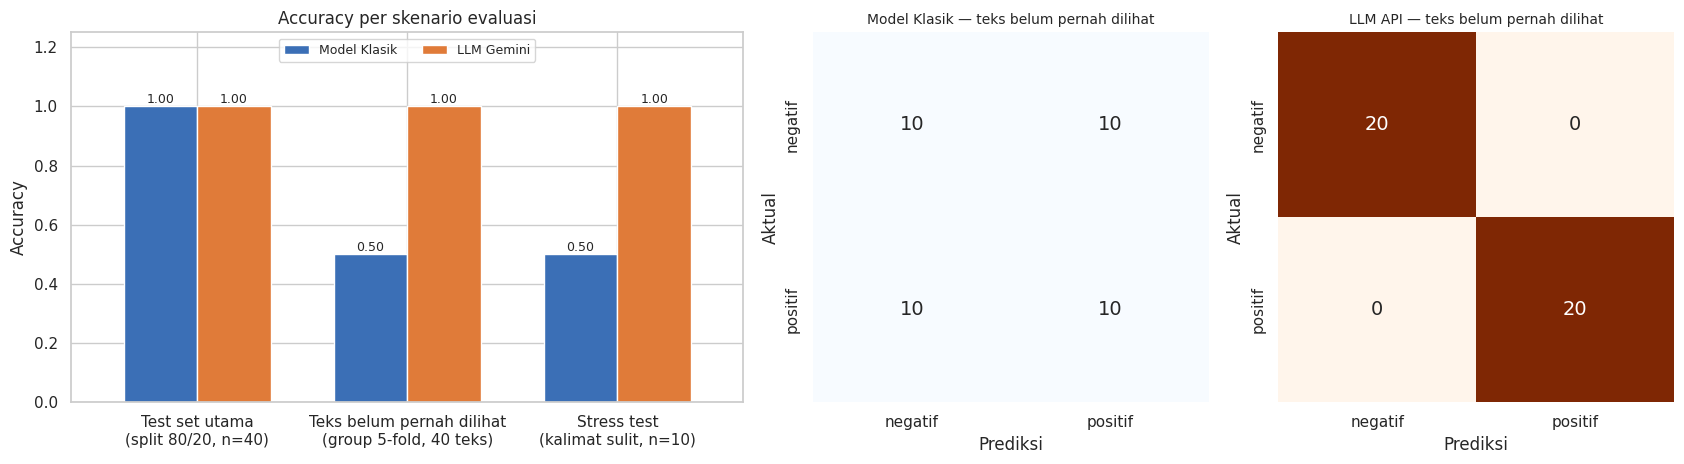

,Model Klasik,LLM Gemini
"Test set utama\n(split 80/20, n=40)",1.0,1.0
"Teks belum pernah dilihat\n(group 5-fold, 40 teks)",0.5,1.0
"Stress test\n(kalimat sulit, n=10)",0.5,1.0


In [23]:
summary = pd.DataFrame({
    'Model Klasik': [res_classic['Accuracy'], res_classic_g['Accuracy'], hard_cases.klasik_benar.mean()],
    'LLM Gemini':   [res_llm['Accuracy'],     res_llm_g['Accuracy'],     hard_cases.llm_benar.mean()],
}, index=['Test set utama\n(split 80/20, n=40)', 'Teks belum pernah dilihat\n(group 5-fold, 40 teks)',
          'Stress test\n(kalimat sulit, n=10)'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.7, 1, 1]})
summary.plot(kind='bar', ax=axes[0], color=['#3B6FB6', '#E07B39'], rot=0, width=0.7)
axes[0].set_ylim(0, 1.25); axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy per skenario evaluasi')
axes[0].legend(loc='upper center', ncol=2, fontsize=9)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.2f', fontsize=9)

for ax, res, cmap in zip(axes[1:], [res_classic_g, res_llm_g], ['Blues', 'Oranges']):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS, annot_kws={'size': 14})
    ax.set_title(res['Pendekatan'], fontsize=10)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout()
fig.savefig(DOC_DIR / 'model_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()
summary.round(2)

In [24]:
# Simpan log seluruh panggilan LLM (raw output, latency, token) untuk audit
full_log = pd.DataFrame(llm_call_log)
full_log.to_csv(DOC_DIR / 'llm_call_log.csv', index=False)
print(f'Total teks unik yang diklasifikasi LLM: {len(full_log)} | sumber: {full_log.source.value_counts().to_dict()}')
print(f'Latency rata-rata {full_log.latency_sec.mean():.2f}s (min {full_log.latency_sec.min():.2f}s, '
      f'max {full_log.latency_sec.max():.2f}s) | output unknown: {(full_log.label == "unknown").sum()}')

Total teks unik yang diklasifikasi LLM: 50 | sumber: {'disk-cache': 50}
Latency rata-rata 0.98s (min 0.80s, max 2.03s) | output unknown: 0


## 7. Analisis Trade-off dan Limitation

### 7.1 Ringkasan hasil

| Skenario evaluasi | Model Klasik (Accuracy / F1 macro) | LLM Gemini (Accuracy / F1 macro) |
|---|---|---|
| Test set utama — split 80/20 yang sama (n=40) | 1.00 / 1.00 | 1.00 / 1.00 |
| Teks belum pernah dilihat — group 5-fold (40 teks unik) | **0.50 / 0.50** | **1.00 / 1.00** |
| Stress test kalimat sulit (n=10, kualitatif) | 5/10 benar | 10/10 benar |

### 7.2 Performa
Di test set utama keduanya seri, tetapi skor model klasik tersebut **tidak valid sebagai ukuran generalisasi**
karena 98% teks test bocor dari train set. Pada teks baru (kondisi yang sebenarnya dihadapi di produksi),
**LLM jelas lebih unggul**: 1.00 vs 0.50. Untuk use case ini metrik terpenting adalah recall kelas `negatif`
(keluhan yang terlewat = masalah yang tidak ditindaklanjuti): LLM 1.00, model klasik 0.50 pada teks baru.

### 7.3 Trade-off

| Aspek | Model Klasik (TF-IDF + LogReg) | LLM API (Gemini 3.5 Flash-Lite) |
|---|---|---|
| Effort implementasi | Butuh data berlabel yang banyak & beragam, proses training, evaluasi, retraining berkala | Tanpa training; cukup prompt engineering + integrasi API |
| Waktu sampai jalan | Cepat *jika* data berlabel sudah ada; lama jika harus melabeli dulu | Sangat cepat (hitungan jam) |
| Kecepatan inferensi | < 0,1 ms/ulasan, bisa batch jutaan data di laptop | ~1 detik/ulasan + terkena rate limit |
| Biaya | Praktis nol (CPU lokal) | ±USD 0,07 per 1.000 ulasan (≈ USD 68 / 1 juta), naik linear dengan volume |
| Generalisasi ke kalimat baru | Lemah pada data sekecil ini | Kuat (zero-shot) |
| Interpretabilitas | Tinggi — bobot tiap kata bisa dilihat | Rendah (*black box*) |
| Konsistensi & kontrol | Deterministik, versi model di tangan sendiri | Bergantung vendor; versi model bisa di-deprecate |
| Privasi & ketergantungan | Data tetap di server sendiri, bisa offline | Teks ulasan dikirim ke pihak ketiga, butuh internet |

### 7.4 Limitation yang ditemukan

**Model klasik**
- Menghafal, bukan memahami: skor sempurna di split yang bocor, tapi 0.50 pada kalimat baru.
- Kata di luar vocabulary (OOV) diabaikan — "memuaskan", "terburuk", slang "mantul" tidak dikenali.
- Negasi hanya tertangkap jika bigram-nya pernah ada di data train ("tidak mengecewakan" gagal saat bigram itu
  tidak ada di train).
- Rentan asosiasi yang salah: "akan order lagi" / "berfungsi" bisa berarti positif atau negatif tergantung konteks.

**LLM API**
- Latency ~1 detik/panggilan dan rate limit → butuh throttling, retry/backoff, dan idealnya proses asinkron/batch.
- Biaya berulang per panggilan; ~90% token input adalah system instruction yang dikirim ulang di setiap panggilan.
- **Ketergantungan vendor terbukti nyata di eksperimen ini:** model di starter (`gemini-2.0-flash`) dan
  `gemini-2.5-flash-lite` sudah tidak tersedia untuk akun baru, sehingga kode harus diubah. Di produksi ini berarti
  perlu pin versi, monitoring, dan re-evaluasi setiap ganti model.
- Skor 1.00 diperoleh pada dataset yang bersih dan eksplisit; performa pada ulasan nyata (typo, campuran, netral,
  sarkasme halus) belum terukur.
- Tidak ada penjelasan kenapa sebuah label dipilih, dan ulasan netral/campuran dipaksa masuk ke dua kelas.

**Eksperimen**
- Dataset sintetis dan sangat repetitif (40 kalimat unik); test set utama hanya 40 baris (26 teks unik).
- Hanya satu varian prompt (zero-shot) dan satu model LLM yang diuji.
- Stress test dilabeli sendiri dan berukuran kecil.

## 8. Rekomendasi Technical Approach

### Rekomendasi: kembangkan **Pendekatan 2 — LLM API (Gemini)** sebagai solusi awal, dengan guardrail produksi, sambil menyiapkan data untuk model sendiri di tahap berikutnya.

**Alasan (berdasarkan hasil eksperimen):**
1. **Generalisasi adalah hal yang paling penting di produksi, dan LLM unggul jauh.** Ulasan baru hampir selalu berupa
   kalimat yang belum pernah dilihat. Pada kondisi ini LLM mencapai accuracy/F1 1.00, sedangkan model klasik hanya
   0.50 (setara tebakan acak) dan melewatkan separuh ulasan negatif.
2. **Skor sempurna model klasik di test set utama tidak bisa dijadikan dasar keputusan**, karena 98% teks test bocor
   dari data train (Section 3 & 6.5).
3. **Data yang ada belum cukup untuk melatih model klasik yang andal.** Dengan hanya 40 kalimat unik, masalahnya ada
   di data, bukan algoritma. LLM tidak membutuhkan data training sehingga fitur bisa dirilis sekarang.
4. **Kelemahan LLM (biaya & latency) masih bisa diterima untuk use case ini.** ±USD 68 per 1 juta ulasan relatif kecil
   untuk platform e-commerce. Latency ~1 detik tidak mengganggu pengguna jika klasifikasi dijalankan **asinkron**
   (saat ulasan dikirim, lalu hasilnya disimpan), bukan saat halaman produk dimuat.

**Guardrail yang disarankan saat implementasi:**
- Pertahankan *constrained output* (enum) + normalisasi output + `temperature=0`.
- Simpan hasil klasifikasi di database (klasifikasi sekali per ulasan, bukan setiap halaman dibuka) dan gunakan
  cache untuk teks identik.
- Pin versi model, catat log (raw output, latency, token), dan jalankan ulang evaluasi ini setiap ganti model/prompt.
- Tambahkan retry + backoff dan fallback (misal status "pending" untuk diproses ulang) jika API gagal.
- Gunakan batch/asynchronous processing serta context caching untuk system instruction agar biaya turun.

**Roadmap jangka menengah (kapan rekomendasi bisa berubah):**
- Kumpulkan ulasan nyata; gunakan label dari LLM + review manusia pada sampel sebagai *ground truth* baru, lalu
  ukur ulang performa pada data yang realistis (termasuk kemungkinan kelas `netral`).
- Jika volume menjadi sangat besar (puluhan juta ulasan/hari), latency harus < 50 ms, atau data tidak boleh keluar
  dari server sendiri, latih model sendiri (TF-IDF + LogReg pada ribuan data beragam, atau fine-tune model seperti
  IndoBERT) memakai data yang sudah dilabeli tersebut. Model klasik menjadi pilihan yang lebih murah dan cepat
  **setelah** datanya cukup — bukan dengan dataset saat ini.